# 3 · A shared space for words and pixels

Suppose the query is **“the purple bar chart.”** The wording describes appearance,
which may be lost in OCR text. Strategy B compares a text representation directly
with an image representation. That only works when the two representations are
deliberately compatible.

Allow **40–55 minutes**. First build a tiny shared color space whose limitations are
obvious. Then inspect the optional real CLIP path. **Color retrieval is not a CLIP
simulation or a benchmark.** It teaches the interface and geometry while making no
claim to understand image meaning.

In [1]:
import os, sys, json, copy
from pathlib import Path
import numpy as np
from IPython.display import display, Image, Markdown
from dotenv import load_dotenv, find_dotenv

# Works when Jupyter starts either here or at the repository root.
candidates = [Path.cwd(), Path.cwd() / "evals" / "multimodal"]
MODULE = next((p for p in candidates if (p / "lab.py").exists()), None)
if MODULE is None:
    raise RuntimeError("Start Jupyter from evals/multimodal or the repository root.")
os.chdir(MODULE)
if str(MODULE) not in sys.path:
    sys.path.insert(0, str(MODULE))
load_dotenv(find_dotenv())  # Secrets live outside the notebook.
from lab import (
    CORPUS, GOLD, Record, LexicalEncoder, ColorEncoder, QdrantIndex,
    load_corpus, load_reference_parses, normalize, validate_parse,
    flatten_parse, build_strategy_a, toy_shared_space, show_hits, rrf,
    evaluate, check_data_points, feature_fingerprint, read_pdf,
    sample_keyframes, build_video_records, timestamp, evidence_bundle,
)
RUN_MODELS = os.getenv("MM_RUN_MODELS") == "1"
RUN_LIVE = os.getenv("MM_RUN_LIVE") == "1"
print("Local pretrained models enabled:", RUN_MODELS)
print("Remote API calls enabled:", RUN_LIVE)
print("Default path: explicit lexical/color baselines, real in-memory Qdrant.")

Local pretrained models enabled: False
Remote API calls enabled: False
Default path: explicit lexical/color baselines, real in-memory Qdrant.


/Users/pmui/dev/agents2026/evals/multimodal/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


![Paired text and image encoders map inputs into one comparison space.](assets/05_strategy_b.svg)

## Step 1 · What does “same space” mean?

In notebook 1, the coordinates `[solar, water, safety]` had an agreed meaning. Imagine
another encoder uses `[water, safety, solar]`. The vectors have the same length, but
their dot product now multiplies the wrong concepts. A model version change can be
subtler than this simple permutation and still break compatibility.

Predict the score before and after an arbitrary coordinate rearrangement. Normalizing
vector lengths cannot restore coordinate meanings that were never aligned.

In [2]:
query_vector = normalize([1., 0., 0.])
aligned_image = normalize([1., 0., 0.])
unrelated_coordinate_order = normalize([0., 0., 1.])
print("Compatible coordinates:", query_vector @ aligned_image)
print("Same dimension, incompatible coordinates:", query_vector @ unrelated_coordinate_order)

Compatible coordinates: 1.0
Same dimension, incompatible coordinates: 0.0


![Equal vector dimensions and normalized lengths do not establish compatible coordinate meanings.](assets/14_coordinate_spaces.svg)

## Step 2 · Design a shared space we completely understand

Our four coordinates are `[orange, purple, green, teal]`. The image encoder measures
how many pixels lie close to four RGB color prototypes. The text encoder looks for
those exact color words. We designed both sides to use the same coordinate order.

This can answer an appearance question such as “purple chart.” It cannot understand
“panel temperature,” read numbers, or distinguish a purple chart from a purple shirt.
A restricted tool is useful when we clearly state what it measures.

In [3]:
raw = load_corpus()
image_records, color_encoder, color_index = toy_shared_space(raw)
color_vectors = color_encoder.embed_images([r.path for r in image_records])
print("Coordinates:", color_encoder.names)
for record, vector in zip(image_records, color_vectors):
    print(record.id, np.round(vector, 3).tolist())

Coordinates: ['orange', 'purple', 'green', 'teal']
chart_energy [1.0, 0.0, 0.018, 0.0]
chart_temperature [0.0, 1.0, 0.021, 0.0]
chart_water [0.0, 0.0, 1.0, 0.0]
screenshot_controller [0.0, 0.0, 0.008, 1.0]


### Open the pixel encoder: measure, count, normalize

Let us compute one image vector without calling `ColorEncoder.embed_images`.
A pixel is three numbers—red, green, blue. We measure its distance to each color
prototype, keep pixels close enough to a prototype, count their nearest colors,
and normalize the four counts. No caption or answer key enters this calculation.

In [4]:
from PIL import Image as PILImage
with PILImage.open(image_records[0].path) as picture:
    small = np.asarray(picture.convert("RGB").resize((160, 104)), dtype=float)
pixel_rows = small.reshape(-1, 3)                  # one RGB triple per row
differences = pixel_rows[:, None, :] - color_encoder.prototypes[None, :, :]
distances = np.sqrt((differences ** 2).sum(axis=2))  # pixel × prototype
nearest_color = distances.argmin(axis=1)
close_enough = distances.min(axis=1) < 65
counts = np.bincount(nearest_color[close_enough], minlength=4)
manual_color_vector = normalize(counts)
print("Counts:", dict(zip(color_encoder.names, counts.tolist())))
print("Same as helper:", np.allclose(manual_color_vector, color_vectors[0]))

Counts: {'orange': 2064, 'purple': 0, 'green': 38, 'teal': 0}
Same as helper: True


The expression `pixel_rows[:, None, :]` inserts an axis so NumPy compares every pixel
with every prototype. The resulting distance table has one row per pixel and four
columns. `argmin` chooses the nearest column. This is an explicit color measurement,
not a learned association between words and images.

These vectors came from actual pixels. Neutral page backgrounds are excluded by the
distance threshold; otherwise the white background would dominate every picture.
Resizing and color thresholds are preprocessing choices, not universal truths.

The image array loses layout. Swapping two bars preserves the color counts, so this
representation cannot know which label belongs to which value. It retains one
property and discards many others—exactly why feature choice matters.

Query vector: [0. 1. 0. 0.]


[{'rank': 1,
  'id': 'chart_temperature',
  'source': 'chart_temperature',
  'modality': 'image',
  'score': 0.9998},
 {'rank': 2,
  'id': 'chart_energy',
  'source': 'chart_energy',
  'modality': 'image',
  'score': 0.0}]

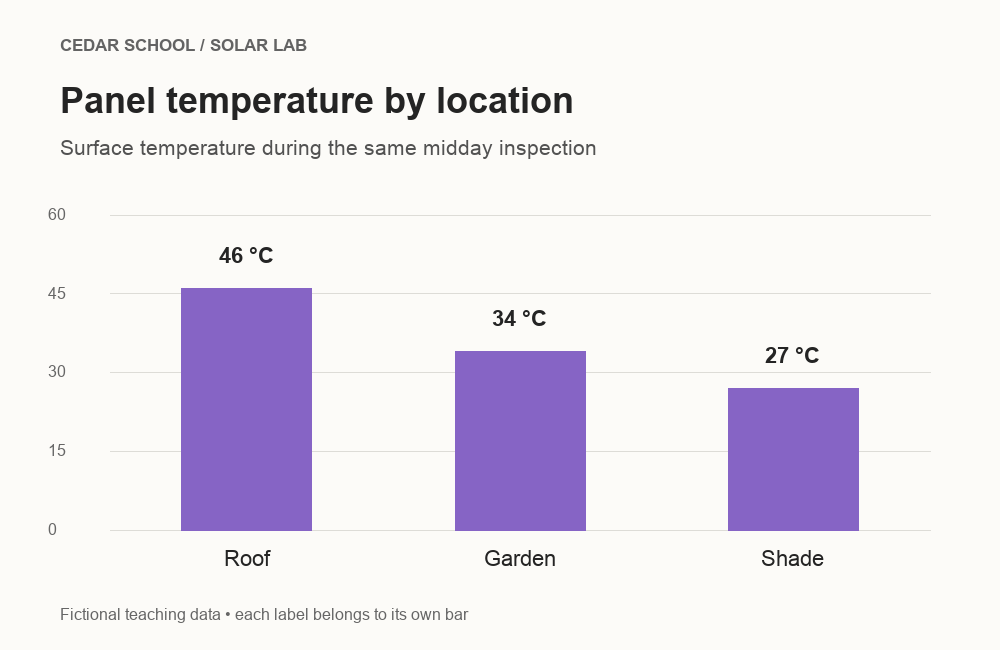

In [5]:
color_query = "the purple bar chart"
color_query_vector = color_encoder.embed_text([color_query])[0]
color_hits = color_index.search(color_query_vector, k=2)
print("Query vector:", color_query_vector)
display(show_hits(color_hits))
display(Image(filename=color_hits[0]["path"], width=650))

The purple chart should be first because its measured pixels match the selected
coordinate. A zero-score second item is merely a requested neighbor, not evidence
that it matches. Our small Qdrant collection breaks ties by stable ID.

**Counterexample:** “Which location has the hottest panel?” is meaningful to a person,
but contains no color word. The next cell should return no color-query direction.
That result is a deliberate honest limitation.

In [6]:
semantic_query = "Which location has the hottest panel?"
q = color_encoder.embed_text([semantic_query])[0]
print("Color-query norm:", np.linalg.norm(q))
print("Color hits:", color_index.search(q, 3))
print("Unknown colors also fail:", color_encoder.embed_text(["red chart"])[0])

Color-query norm: 0.0
Color hits: []
Unknown colors also fail: [0. 0. 0. 0.]


## Step 3 · Understand what CLIP learns instead

CLIP uses two neural networks, often called **towers**: one reads text tokens and one
reads image pixels. During training, matched image/caption pairs are encouraged to
have larger similarities than mismatched pairs. Repeating this across many examples
teaches useful associations. At search time, the trained encoders are reused; we
are **not training CLIP** in this tutorial.

“Contrastive” means learning by comparing a match with alternatives. The little matrix
below is a made-up training illustration, not measured CLIP output. A diagonal entry
represents the intended image/caption pairing. Large diagonal values would be useful,
but a training objective cannot guarantee perfect behavior on every new image.

In [7]:
illustrative_scores = np.array([[0.8, 0.2, 0.1],
                                [0.1, 0.7, 0.3],
                                [0.2, 0.1, 0.9]])
print("Illustrative similarity matrix: rows = images; columns = paired captions")
print(illustrative_scores)
print("Best caption per image:", illustrative_scores.argmax(axis=1))

Illustrative similarity matrix: rows = images; columns = paired captions
[[0.8 0.2 0.1]
 [0.1 0.7 0.3]
 [0.2 0.1 0.9]]
Best caption per image: [0 1 2]


A useful CLIP feature may capture objects, style, or scene type while missing exact
chart arithmetic. The phrase “largest May value” is much more specific than “a bar
chart.” Tiny OCR, subtle spatial relationships, and precise counts need testing.

Paired training makes cross-modal comparison meaningful; it does not force image and
text vectors to occupy identical distributions. In a joint collection, one modality
can crowd out the other. This **modality gap** is a reason to inspect results by
modality and compare joint retrieval with separate-store retrieval.

## Step 4 · Optional real CLIP through FastEmbed

With `MM_RUN_MODELS=1`, the next cell downloads/loads the paired ONNX models
`Qdrant/clip-ViT-B-32-text` and `Qdrant/clip-ViT-B-32-vision`, plus the small BGE
text model used by our shared helper. Inference runs locally after the model files
are available. Initial downloads require network access and disk space.

The text and vision towers must come from the intended pair; equal dimensions alone
are insufficient. CLIP's text context is limited. Do not assume `text[:300]` meets a
token limit: characters and tokens differ. These short examples avoid manual character
truncation; for longer sources, use the model's tokenizer to measure and chunk text.

In [8]:
real_b_index = None
if RUN_MODELS:
    from live import FastEmbedModels
    real_models = FastEmbedModels()
    text_records = [r for r in raw if r.modality == "text"]
    text_vectors = real_models.clip_texts([r.text for r in text_records])
    image_vectors = real_models.clip_images([r.path for r in image_records])
    assert text_vectors.shape[1] == image_vectors.shape[1]
    real_b_index = QdrantIndex(text_records + image_records,
                              np.vstack([text_vectors, image_vectors]), "real_joint_clip")
    real_query = real_models.clip_texts(["purple bar chart of panel temperature"])[0]
    display(show_hits(real_b_index.search(real_query, 5)))
    print("Actual local CLIP results; not color-baseline results.")
else:
    print("Real CLIP skipped. No learned-model performance is inferred from the color lesson.")

Real CLIP skipped. No learned-model performance is inferred from the color lesson.


In this optional joint collection, both memos and images are encoded through CLIP's
paired space. We did **not** mix BGE text vectors into a CLIP collection. A joint
ranking answers “which stored representation is closest?” It may still favor one
modality for a query. A modality filter lets us inspect that behavior directly.

In [9]:
if real_b_index is not None:
    for query in ["monthly solar energy", "E17 ventilation blocked", "purple bar chart"]:
        q = real_models.clip_texts([query])[0]
        print("\nQuery:", query)
        print("Joint:", [h["id"] for h in real_b_index.search(q, 3)])
        print("Image-only:", [h["id"] for h in real_b_index.search(q, 3, modality="image")])
else:
    print("Joint-versus-image CLIP comparison requires the optional model path.")

Joint-versus-image CLIP comparison requires the optional model path.


A filter changes the candidate set. It does not improve the encoder's ability to read
`E17`, and it may remove a useful memo. Query policies should follow user needs and
measured relevance. Do not declare one approach best from a single attractive result.
Notebook 4 uses a small common evaluation set and separates question types.

## Step 5 · Separate the similarity score from evidence

A high image/text score says “these representations are near each other.” It does not
compute the chart's maximum value. For a numeric question, retrieve the image and
then inspect its labels and units. A broad-image encoder can still be useful even
when a specialized reader is needed afterward.

Let's make the information loss visible: rearrange all pixels in the chart. The
histogram of exact colors stays the same, while the picture becomes unreadable.
We inspect histograms in memory and do not replace the source image.

Exact color counts unchanged: True


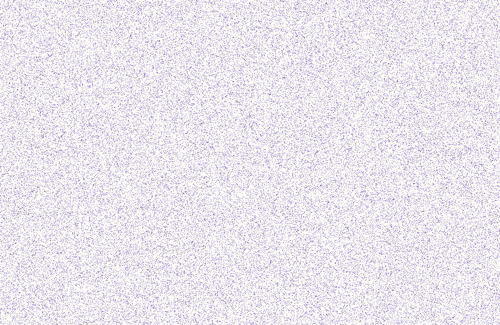

In [10]:
from PIL import Image as PILImage
path = next(r.path for r in raw if r.id == "chart_temperature")
with PILImage.open(path) as picture:
    pixels = np.asarray(picture.convert("RGB"))
shuffled = pixels.reshape(-1, 3).copy()
np.random.default_rng(7).shuffle(shuffled, axis=0)
original_counts = np.unique(pixels.reshape(-1, 3), axis=0, return_counts=True)[1]
shuffled_counts = np.unique(shuffled, axis=0, return_counts=True)[1]
print("Exact color counts unchanged:", np.array_equal(original_counts, shuffled_counts))
display(PILImage.fromarray(shuffled.reshape(pixels.shape)).resize((500, 325)))

The image is now noise, but a color histogram cannot tell. Our resize-based encoder
adds a preprocessing step, so its measured vector may also change slightly when
resizing mixes neighboring pixels; the fundamental information-loss point is about
histograms, not a claim of exact invariance for every preprocessing pipeline.

CLIP is much richer than a histogram. The lesson transfers: inspect what any
representation preserves and what the task demands. “It is an embedding” does not
specify the kinds of evidence it can retain.

![Feature generation records source, model, preprocessing, and version so stale embeddings can be replaced.](assets/12_feature_lifecycle.svg)

## Step 6 · Save the representation contract

A usable image-feature record includes a source checksum, model identifier/version,
preprocessing policy, dimension, and original media path. Store and query features
with the same contract. If you switch from one CLIP version to another, re-embed;
if you crop an image differently, record that change too.

Color vectors need the same discipline. Their four coordinates mean nothing if a
future query encoder silently changes the order to `[green, teal, purple, orange]`.
Read [FEATURE_STORES.md](FEATURE_STORES.md) for how this relates to feature storage,
freshness, lineage, and point-in-time correctness.

In [11]:
record = image_records[0]
contract = feature_fingerprint(record, "color-prototypes-v1", "no-parser", "RGB;160x104;distance<65")
contract.update({"dimension": 4, "coordinate_order": color_encoder.names, "source_id": record.source_id})
display(contract)

{'source_sha256': '53d972213e2a1b1fb22e8184196efdc10e7eee5b439646c1d3affdb5ec3fb970',
 'model_id': 'color-prototypes-v1',
 'parser_version': 'no-parser',
 'preprocessing': 'RGB;160x104;distance<65',
 'feature_key': '79e4ad0c8ccaca188b30d629f8d7f8d3d0bd72daea3b3e71c72f5399148a7b92',
 'dimension': 4,
 'coordinate_order': ['orange', 'purple', 'green', 'teal'],
 'source_id': 'chart_energy'}

### Exercise · Pick a representation

For each query, choose a plausible first retrieval route and say what still needs
verification: (a) “a purple chart,” (b) “what does E17 mean?”, (c) “how much energy
did May produce?”, (d) “a picture of a shaded garden.”

<details><summary>Worked answers</summary>

(a) Color or learned visual features can help; inspect that the result is actually a
chart. (b) Exact OCR/caption/lexical matching is useful; verify the code's nearby
message. (c) Search chart descriptions or a learned space for energy, then read May's
value and unit. (d) A pretrained shared model is a plausible route, but our color
encoder cannot understand “garden.” Test against labelled image relevance.
</details>

Next: [04 · Fuse rankings and evaluate honestly](04_fusion_and_evaluation.ipynb).
Source connections: reference cells 25–28 (CLIP towers and joint collection),
plus the CLIP paper linked in THEORY.md. Our color lesson is an original teaching
baseline; it is never substituted for measured CLIP behavior.